## Problema y objetivos

La empresa quiere identificar el género de una canción a partir de sus características de audio. La variable `id_genero` no es una etiqueta de sí o no, ni un valor numérico a estimar: toma 10 valores distintos y cada canción pertenece a una sola clase. El problema es de **clasificación supervisada multiclase**.

En este notebook el objetivo es entrenar un XGBoost que, a partir de las características de 30 segundos de cada canción, le asigne una de esas 10 clases. El modelo se ajusta solo con las canciones de entrenamiento; el conjunto de test se reserva para la evaluación. El resultado se mide con accuracy y F1 macro, para ver el acierto global y el rendimiento medio entre géneros.

## Selección de métricas y umbral

**Accuracy.** Hay 10 géneros y el mismo número de canciones en cada clase. Con ese reparto equilibrado, el porcentaje de aciertos resume el rendimiento global sin que una clase más frecuente lo distorsione.

**F1 macro.** Se calcula el F1 de cada género y se promedia dando el mismo peso a las 10 clases. Así, un género fácil de clasificar no compensa a otro que el modelo confunde. El F1 por clase del informe de clasificación muestra cuáles son esos géneros.

**Umbral de decisión.** El modelo devuelve una probabilidad para cada una de las 10 clases. La clase asignada es la de probabilidad más alta. No se exige una probabilidad mínima para aceptar la predicción: si la clase ganadora tiene, por ejemplo, 0,2 y el resto queda por debajo, esa clase se predice igualmente.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import GridSearchCV

In [ ]:
from pathlib import Path

def carpeta_proyecto(nombre, marca):
    """Localiza los CSV en Jupyter, Visual Studio Code y Colab."""
    from pathlib import Path
    import json

    saltar = {
        ".config", "sample_data", "drive", ".git", "__pycache__",
        "node_modules", ".ipynb_checkpoints", "site-packages",
    }

    def directorio_notebook():
        try:
            return Path(__vsc_ipynb_file__).resolve().parent
        except NameError:
            pass
        try:
            from urllib.request import urlopen
            try:
                from ipykernel.connect import get_connection_file
            except ImportError:
                from ipykernel import get_connection_file
            conexion = Path(get_connection_file())
            kernel_id = conexion.name.replace("kernel-", "").replace(".json", "")
            servidores = list(conexion.parent.glob("jpserver-*.json"))[:3]
            for servidor in servidores:
                try:
                    info = json.loads(servidor.read_text(encoding="utf-8"))
                except (OSError, json.JSONDecodeError):
                    continue
                url = str(info.get("url", "")).rstrip("/")
                raiz = info.get("root_dir")
                if not url or not raiz:
                    continue
                api = url + "/api/sessions"
                token = info.get("token") or ""
                if token:
                    api += "?token=" + token
                try:
                    with urlopen(api, timeout=0.8) as respuesta:
                        sesiones = json.loads(respuesta.read().decode())
                except Exception:
                    continue
                for sesion in sesiones:
                    kid = (sesion.get("kernel") or {}).get("id")
                    if kid != kernel_id:
                        continue
                    cuaderno = sesion.get("notebook") or {}
                    relativo = cuaderno.get("path") or sesion.get("path")
                    if relativo:
                        return (Path(raiz) / relativo).resolve().parent
        except Exception:
            pass
        return None

    bases = []
    notebook = directorio_notebook()
    if notebook is not None:
        bases.append(notebook)
    bases.append(Path.cwd().resolve())
    content = Path("/content")
    if content.is_dir():
        bases.append(content)
        drive = content / "drive" / "MyDrive"
        if drive.is_dir():
            bases.append(drive)

    nombradas = []
    sueltas = []
    vistos = set()

    def considerar(directorio, aceptar_suelto):
        if directorio in vistos:
            return
        vistos.add(directorio)
        try:
            carpeta = directorio / nombre
            if (carpeta / marca).is_file():
                nombradas.append(carpeta)
                return
            if directorio.name == nombre and (directorio / marca).is_file():
                nombradas.append(directorio)
                return
            if aceptar_suelto and (directorio / marca).is_file():
                sueltas.append(directorio)
        except OSError:
            return

    def hijos(directorio, profundidad, limite):
        if profundidad < 0 or limite[0] <= 0 or not directorio.is_dir():
            return
        try:
            entradas = list(directorio.iterdir())
        except OSError:
            return
        for hijo in entradas:
            if not hijo.is_dir() or hijo.name.startswith(".") or hijo.name in saltar:
                continue
            limite[0] -= 1
            considerar(hijo, False)
            if nombradas or limite[0] <= 0:
                return
            hijos(hijo, profundidad - 1, limite)
            if nombradas or limite[0] <= 0:
                return

    for base in bases:
        considerar(base, True)
        if nombradas:
            break
        for padre in list(base.parents)[:6]:
            considerar(padre, False)
            if nombradas:
                break
        if nombradas:
            break
        profundidad = 3 if base.name in {"content", "MyDrive"} else 2
        hijos(base, profundidad, [400])
        if nombradas:
            break

    if nombradas:
        return nombradas[0]
    if sueltas:
        return sueltas[0]
    raise FileNotFoundError(
        "No se encuentra " + marca + ". "
        "Tiene que existir la carpeta '" + nombre + "' en el proyecto, "
        "o el archivo en el directorio de trabajo. En Colab puede estar junto a sample_data."
    )


def carpeta_datos():
    """Carpeta datos preprocesados, en Jupyter, Visual Studio Code o Colab."""
    return carpeta_proyecto("datos preprocesados", "ids_train.csv")

DATOS = carpeta_datos()
print("Datos:", DATOS)

#Cargamos los datos, y la seleccion que hemos decidido para train y test
df = pd.read_csv(DATOS / "df_cancion_30s.csv")
ids_train = pd.read_csv(DATOS / "ids_train.csv")['id_cancion']
ids_test = pd.read_csv(DATOS / "ids_test.csv")['id_cancion']

In [ ]:
display(df)

,id_cancion,cancion,duracion,coste,id_genero,id_disco,id_autor,id_discografica,filename_30s,length_30s,...,mfcc16_var_30s,mfcc17_mean_30s,mfcc17_var_30s,mfcc18_mean_30s,mfcc18_var_30s,mfcc19_mean_30s,mfcc19_var_30s,mfcc20_mean_30s,mfcc20_var_30s,label_30s
0,1,blues.00000.wav,138.0,744.01,1,1,1,1,blues.00000.wav,661794,...,52.420910,-1.690215,36.524071,-0.408979,41.597103,-2.303523,55.062923,1.221291,46.936035,blues
1,2,blues.00001.wav,142.0,4178.85,1,2,2,2,blues.00001.wav,661794,...,55.356403,-0.731125,60.314529,0.295073,48.120598,-0.283518,51.106190,0.531217,45.786282,blues
2,3,blues.00002.wav,96.0,3226.40,1,3,4,3,blues.00002.wav,661794,...,40.598766,-7.729093,47.639427,-1.816407,52.382141,-3.439720,46.639660,-2.231258,30.573025,blues
3,4,blues.00003.wav,111.0,3618.77,1,4,6,4,blues.00003.wav,661794,...,44.427753,-3.319597,50.206673,0.636965,37.319130,-0.619121,37.259739,-3.407448,31.949339,blues
4,5,blues.00004.wav,191.0,1990.81,1,5,7,5,blues.00004.wav,661794,...,86.099236,-5.454034,75.269707,-0.916874,53.613918,-4.404827,62.910812,-11.703234,55.195160,blues
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996,rock.00095.wav,101.0,3185.88,10,197,306,25,rock.00095.wav,661794,...,45.050526,-13.289984,41.754955,2.484145,36.778877,-6.713265,54.866825,-1.193787,49.950665,rock
996,997,rock.00096.wav,170.0,-503.65,10,194,321,1,rock.00096.wav,661794,...,33.851742,-10.848309,39.395096,1.881229,32.010040,-7.461491,39.196327,-2.795338,31.773624,rock
997,998,rock.00097.wav,121.0,2170.05,10,189,297,9,rock.00097.wav,661794,...,33.597008,-12.845291,36.367264,3.440978,36.001110,-12.588070,42.502201,-2.106337,29.865515,rock
998,999,rock.00098.wav,99.0,1425.79,10,187,301,20,rock.00098.wav,661794,...,46.324894,-4.416050,43.583942,1.556207,34.331261,-5.041897,47.227180,-3.590644,41.299088,rock


#Preparación de los datos

In [ ]:
#Aunque este modelo admite los valores nulos, veamos si hay
df.columns[df.isnull().sum()>0]

Index(['duracion'], dtype='object')

In [ ]:
df['duracion'].isnull().sum()

np.int64(18)

In [ ]:
display(ids_train)
display(ids_test)

,id_cancion
0,576
1,205
2,965
3,504
4,503
...,...
795,916
796,347
797,931
798,307


,id_cancion
0,172
1,93
2,671
3,536
4,22
...,...
195,238
196,270
197,107
198,984


In [ ]:
#Separamos en train/test
df_train = df[df['id_cancion'].isin(ids_train)].copy()
df_test = df[df['id_cancion'].isin(ids_test)].copy()

In [ ]:
# Para este modelo se utilizan únicamente variables numéricas.Las columnas de tipo object y los identificadores se eliminan para evitar
#problemas de codificación y reducir ruido en el entrenamiento.
X_train = df_train.drop(columns=['id_genero','cancion','filename_30s','label_30s','id_cancion','id_disco','id_autor','id_discografica'])
y_train = df_train['id_genero']
X_test = df_test.drop(columns=['id_genero','cancion','filename_30s','label_30s','id_cancion','id_disco','id_autor','id_discografica'])
y_test = df_test['id_genero']

In [ ]:
#Codificamos la variable y para cambiar el rango de 1-10 a 0-9, y así garantizar la compatibilidad con el algoritmo
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

#Construcción del modelo XGBOOST

In [ ]:
#Miramos cuales son los parametros óptimos
param = {
    'n_estimators': [100, 300, 500],        # nº de árboles
    'max_depth': [3, 5, 7],                 # profundidad máxima
    'learning_rate': [0.01, 0.05, 0.1],     # velocidad de aprendizaje
    'subsample': [0.8, 1.0],                # % de filas usadas por árbol
    'colsample_bytree': [0.8, 1.0]          # % de columnas usadas por árbol
}

grid = GridSearchCV(
    XGBClassifier(),
    param,
    cv=5,
    n_jobs=-1,
    return_train_score=True
)

grid.fit(X_train, y_train)

print("Mejores parámetros:")
print(grid.best_params_)

Mejores parámetros:
{'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 500, 'subsample': 0.8}


In [ ]:
#Modelo
modelo_xgb=XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=1.0,
    objective = 'multi:softmax'
)

#Entrenamiento del modelo

In [ ]:
modelo_xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=1.0, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=500,
              n_jobs=None, num_parallel_tree=None, ...)

#Evaluación y predicción del modelo

In [ ]:
#Evaluación
acc_xgb = modelo_xgb.score(X_test,y_test)

print('Accuracy of XGBoost: %2.2f '%(100*acc_xgb))

Accuracy of XGBoost: 78.00 


In [ ]:
#Predicción
y_pred = modelo_xgb.predict(X_test)
y_pred

array([8, 0, 0, 0, 0, 0, 0, 0, 0, 8, 0, 0, 0, 2, 0, 0, 0, 0, 5, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 5, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 5, 2,
       2, 2, 2, 9, 2, 2, 2, 2, 2, 2, 8, 2, 2, 8, 2, 2, 4, 3, 8, 2, 3, 2,
       4, 3, 3, 7, 3, 3, 3, 3, 6, 3, 6, 4, 3, 4, 4, 6, 4, 0, 0, 4, 4, 3,
       4, 4, 4, 4, 3, 4, 4, 4, 4, 4, 4, 4, 1, 5, 5, 5, 5, 5, 5, 5, 5, 5,
       5, 5, 5, 5, 5, 5, 9, 5, 5, 5, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6,
       6, 3, 6, 6, 6, 8, 6, 6, 7, 7, 7, 3, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
       7, 8, 7, 7, 7, 7, 8, 8, 8, 8, 8, 8, 8, 8, 7, 8, 8, 8, 8, 8, 8, 8,
       7, 8, 7, 8, 0, 0, 9, 9, 2, 9, 9, 3, 4, 2, 9, 5, 5, 5, 9, 0, 0, 9,
       9, 9], dtype=int32)

In [ ]:
#Deshacemos el LabelEncoder
y_test_original = le.inverse_transform(y_test)
y_pred_original = le.inverse_transform(y_pred)

In [ ]:
print("            Métricas de evaluación por género musical")
print(classification_report(y_test_original, y_pred_original))

            Métricas de evaluación por género musical
              precision    recall  f1-score   support

           1       0.73      0.80      0.76        20
           2       0.95      0.95      0.95        20
           3       0.76      0.80      0.78        20
           4       0.67      0.50      0.57        20
           5       0.75      0.75      0.75        20
           6       0.75      0.90      0.82        20
           7       0.86      0.90      0.88        20
           8       0.82      0.90      0.86        20
           9       0.71      0.85      0.77        20
          10       0.82      0.45      0.58        20

    accuracy                           0.78       200
   macro avg       0.78      0.78      0.77       200
weighted avg       0.78      0.78      0.77       200



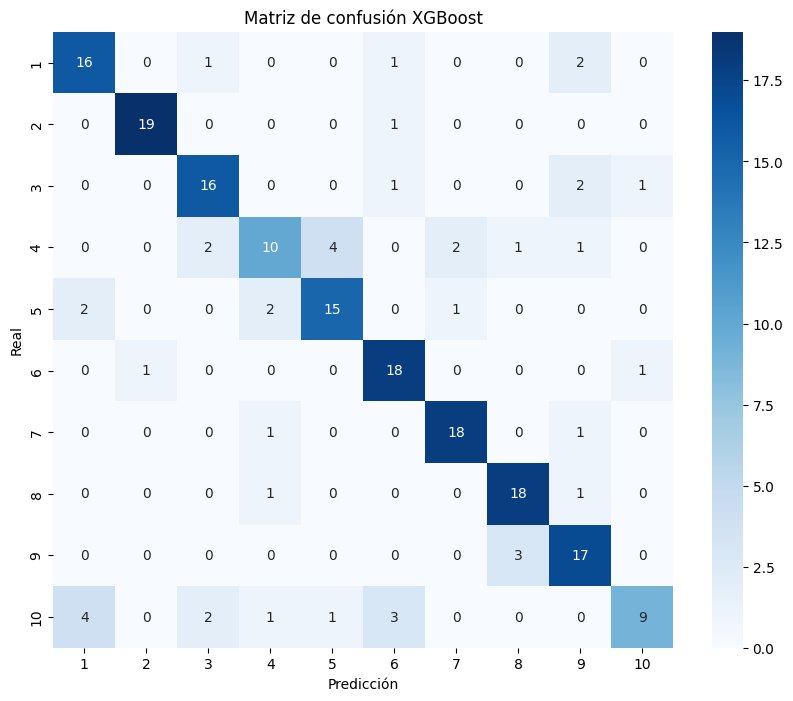

In [ ]:
#Matriz de confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10,8))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=np.unique(y_test_original),
            yticklabels=np.unique(y_test_original))

plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de confusión XGBoost')
plt.show()

#Conclusión

El modelo XGBoost obtuvo una precisión global del 78% sobre el conjunto de prueba. Según el Classification Report, las métricas de precisión, recall
y F1-score presentan valores cercanos al 0,78 de media, lo que indica un rendimiento equilibrado en la mayoría de las clases.
Destacan especialmente las clases 2, 7 y 8, con valores de F1-score superiores a 0,88, mientras que las clases 4 y 10 presentan un comportamiento
más complejo y obtienen los resultados más bajos.

La matriz de confusión confirma estos resultados, mostrando una elevada concentración de predicciones correctas en la diagonal principal.
No obstante, se observan algunas confusiones entre determinados géneros musicales, especialmente en las clases 4, 5 y 10,
lo que sugiere que comparten características similares que dificultan su diferenciación por parte del modelo.

Los resultados obtenidos indican que XGBoost es capaz de identificar correctamente la mayoría de los géneros musicales presentes
en el conjunto de datos, alcanzando un nivel de rendimiento satisfactorio para una tarea de clasificación multiclase.